# Projet signaux 3 — traitement d'une photo de pièce

`main.ipynb` est le fichier central : on y choisit la photo et on enchaîne les traitements. Les fonctions de traitement sont rangées dans des fichiers Python séparés, dans le dossier `modules/`.

Le principe est : une fonction reçoit une image, fait une étape, puis la **renvoie**. On garde ce résultat dans une variable pour l'étape suivante.


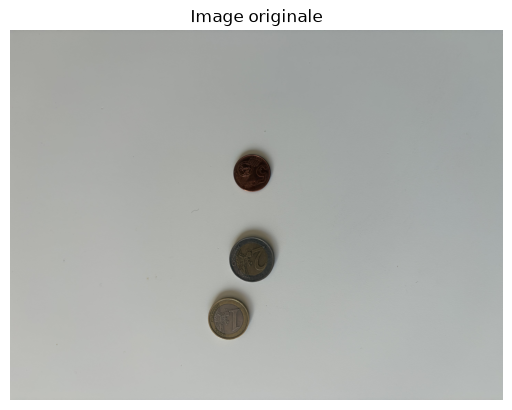

In [18]:
# Charger et afficher l’image originale

from pathlib import Path
import matplotlib.pyplot as plt

chemin_photo = Path("images_test/euro-50.jpeg")
image_originale = plt.imread(chemin_photo)

plt.imshow(image_originale)
plt.title("Image originale")
plt.axis("off")
plt.show();


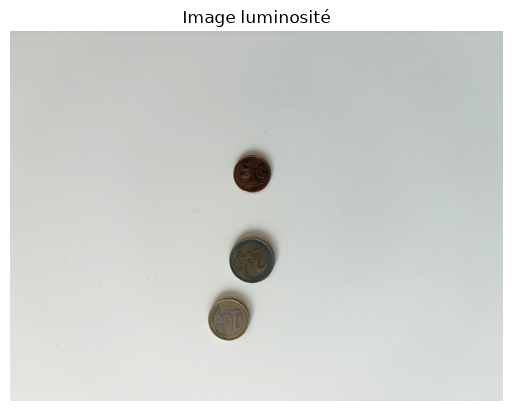

In [19]:
# Ameliorer la luminosté

from modules.luminosite import ameliorer_luminosite

image_lum = ameliorer_luminosite(image_originale)
plt.imshow(image_lum)
plt.title("Image luminosité")
plt.axis("off");


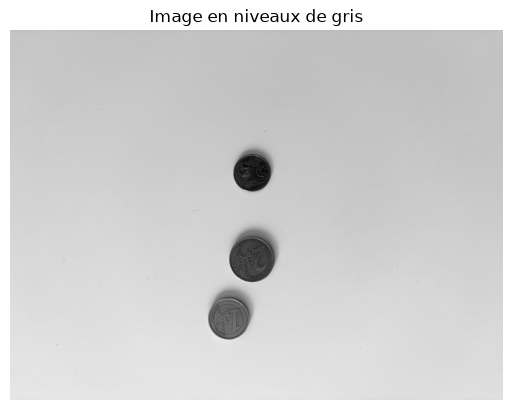

In [20]:
# Convertir l’image en niveaux de gris

from modules.niveaux_gris import convertir_en_gris

image_grise = convertir_en_gris(image_lum)

plt.imshow(image_grise, cmap="gray")
plt.title("Image en niveaux de gris")
plt.axis("off");


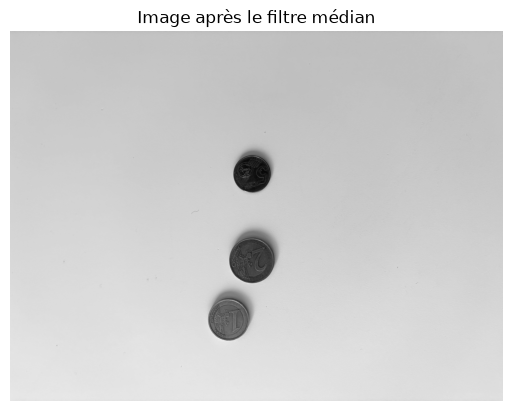

In [21]:
# Réduire le bruit avec un filtre médian

from modules.filtre_median import appliquer_filtre_median

image_filtree = appliquer_filtre_median(image_grise)

plt.imshow(image_filtree, cmap="gray")
plt.title("Image après le filtre médian")
plt.axis("off");


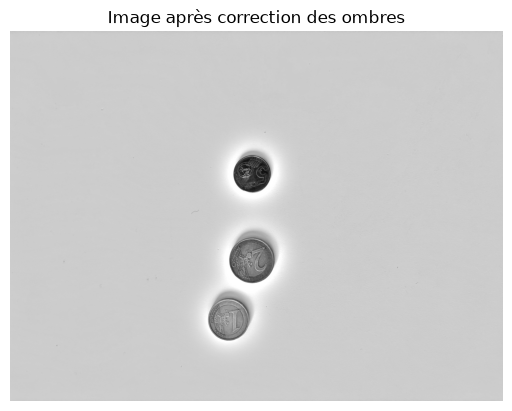

In [22]:
# Estimer l’éclairage et corriger les ombres

from modules.flou_gaussien import corriger_ombres

image_corrigee = corriger_ombres(image_filtree, sigma=150)
plt.imshow(image_corrigee, cmap="gray")
plt.title("Image après correction des ombres")
plt.axis("off");


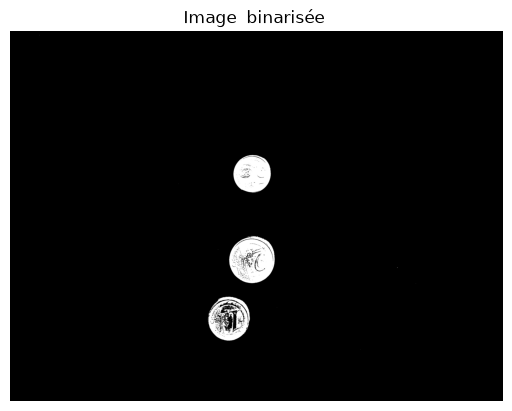

In [23]:
# Binariser l’image

from modules.binarisation import img_binarisee
image_binarisee = img_binarisee(image_corrigee)
plt.imshow(image_binarisee,cmap="gray");
plt.title("Image  binarisée ");
plt.axis("off");

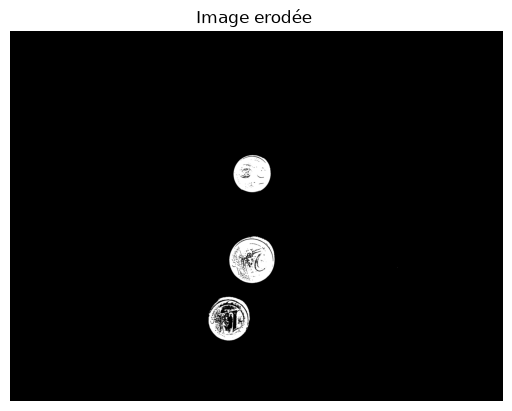

In [24]:
# nettoyer le masque binaire et améliorer les formes des pièces

from modules.erosion import appliquer_erosion

image_erodee = appliquer_erosion(image_binarisee, rayon=1)
plt.imshow(image_erodee,cmap="gray");
plt.title("Image erodée ");
plt.axis("off");


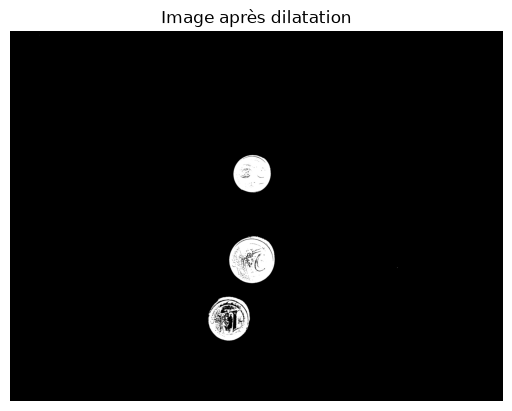

In [25]:
# Dilater le résultat après l’érosion

from modules.dilatation import appliquer_dilatation

image_dilatee = appliquer_dilatation(image_erodee, rayon=1)
plt.imshow(image_dilatee, cmap="gray")
plt.title("Image après dilatation")
plt.axis("off");


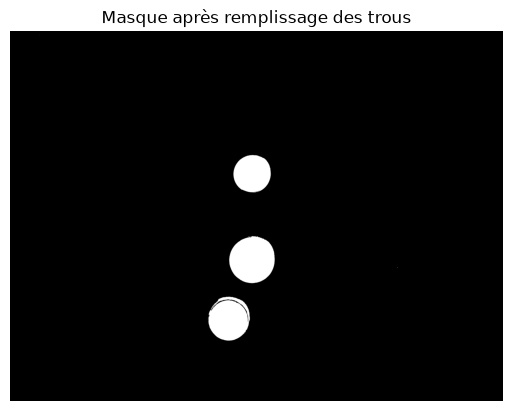

In [26]:
# Remplir les trous du masque

from modules.remplissage_trous import remplir_trous

image_sans_trous = remplir_trous(image_dilatee)
plt.imshow(image_sans_trous, cmap="gray")
plt.title("Masque après remplissage des trous")
plt.axis("off");


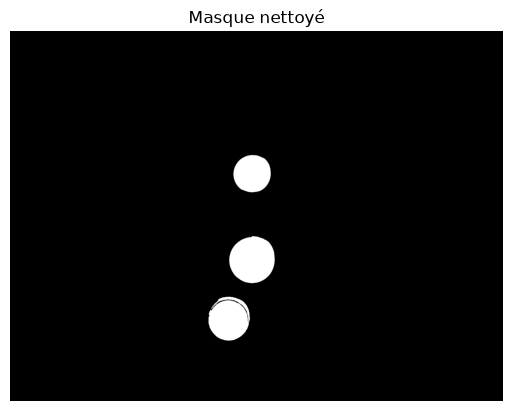

In [27]:
# Supprimer les petites régions parasites

from modules.nettoyage_masque import supprimer_petits_objets

image_masque_propre = supprimer_petits_objets(image_sans_trous, taille_min=5000)
plt.imshow(image_masque_propre, cmap="gray")
plt.title("Masque nettoyé")
plt.axis("off");


Nombre de régions détectées : 3


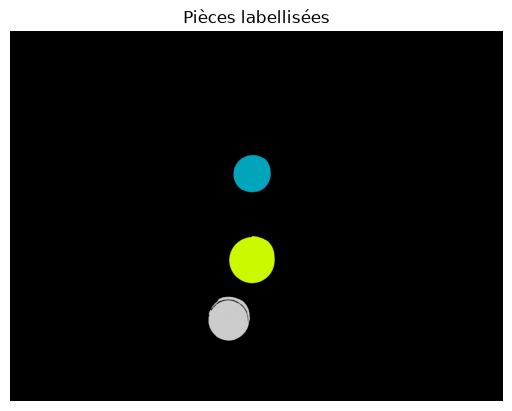

In [28]:
# Labelliser les pièces détectées

from modules.labellisation import labelliser_objets, compter_objets

image_labellisee = labelliser_objets(image_masque_propre, connectivite=1)
nombre_pieces = compter_objets(image_labellisee)
print(f"Nombre de régions détectées : {nombre_pieces}")
plt.imshow(image_labellisee, cmap="nipy_spectral")
plt.title("Pièces labellisées")
plt.axis("off");


In [29]:
# tableau des pieces + colorisation
from modules.labellisation import mesurer_objets
import pandas as pd


tableau_images = pd.DataFrame(mesurer_objets(image_labellisee,image_originale))
tableau_images

,piece,aire (en px),périmètre(en px),Couleur
0,1,148629.0,1556.82,Cuivre
1,2,224917.0,1865.67,Bicolor
2,3,186728.0,3278.34,Bicolor


In [30]:
# colorisation
from modules.calcul import identifier_piece,calcul_montant

pieces = mesurer_objets(image_labellisee,image_originale)

liste_montant = []

for piece in pieces:
    montant = identifier_piece(
        piece["aire (en px)"],
        piece["Couleur"]
    )
    if montant is None:
        print(f"Pièce inconnue : aire = {piece['aire (en px)']}, couleur = {piece['Couleur']}")
    else:
        liste_montant.append(montant)

montant_total = calcul_montant(liste_montant)
nombre_inconnues = len(pieces) - len(liste_montant)

if nombre_inconnues:
    print(f"Montant partiel : {montant_total/100} Euros ({nombre_inconnues} pièce(s) inconnue(s))")
else:
    print(f"Montant total : {montant_total/100} Euros")

Montant total : 3.05 Euros
